In [13]:
import os
import subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation")
except Exception:
    ss_ready = False

if not ss_ready:
    subprocess.run(
        "pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless",
        shell=True
    )
    subprocess.run("pip install -q opencv-contrib-python", shell=True)
    os.kill(os.getpid(), 9)

In [14]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

In [15]:
def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()
        boxes = [
            (x, y, w, h)
            for (x, y, w, h) in ss.process()
            if w > 40 and h > 40
        ]
        if boxes:
            return boxes[:max_regions]
    except Exception:
        pass

    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W * s), int(H * s)

        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]

In [16]:
def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array(
        [[x, y, x + w, y + h] for (x, y, w, h), _, _ in dets],
        dtype=float
    )
    scores = np.array([s for _, _, s in dets])

    order = scores.argsort()[::-1]
    keep = []

    while len(order):
        i = order[0]
        keep.append(i)
        rest = order[1:]

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        area_i = (boxes[i, 2] - boxes[i, 0]) * (boxes[i, 3] - boxes[i, 1])
        area_r = (boxes[rest, 2] - boxes[rest, 0]) * (boxes[rest, 3] - boxes[rest, 1])

        iou = inter / (area_i + area_r - inter + 1e-9)
        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]

In [17]:
model = VGG16(weights="imagenet", include_top=True)

Saving traffic.jpg to traffic (4).jpg


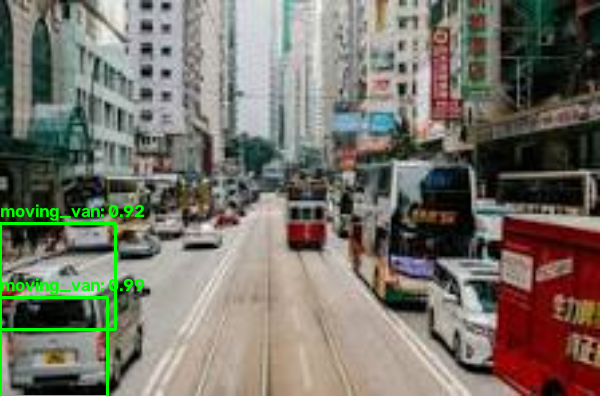

In [20]:
uploaded = files.upload()
image_path = next(iter(uploaded))

img = cv2.imread(image_path)
HO, WO = img.shape[:2]
img = cv2.resize(img, (600, int(HO * 600.0 / WO)))

boxes = get_region_proposals(img, max_regions=200)

crops = np.array(
    [
        cv2.resize(img[y:y+h, x:x+w], (224, 224))
        for (x, y, w, h) in boxes
    ],
    dtype=np.float32
)

preds = model.predict(
    preprocess_input(crops),
    batch_size=32,
    verbose=0
)

detections = []

for (x, y, w, h), p in zip(boxes, preds):
    _, label, prob = decode_predictions(p[None], top=1)[0][0]

    if prob > 0.90:
        detections.append(((x, y, w, h), label, float(prob)))

detections = non_max_suppression(detections, iou_thr=0.3)

for (x, y, w, h), label, score in detections:
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(
        img,
        f"{label}: {score:.2f}",
        (x, max(18, y - 6)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

cv2_imshow(img)